Imports

In [1]:
import os, pathlib, numpy as np, tensorflow as tf
from tensorflow.keras import layers, models

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

Scarica il dataset

In [2]:
tf.keras.utils.get_file(
    'mini_speech_commands.zip',
    origin="http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip",
    extract=True, cache_dir='.', cache_subdir='data')

data_dir = pathlib.Path('data/mini_speech_commands_extracted/mini_speech_commands')
commands = np.array(['yes', 'no', 'stop', 'go'])
print("Classi:", commands)

182082353/182082353 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Classi: ['yes' 'no' 'stop' 'go']


Preprocessing

In [3]:
def get_spectrogram(waveform):
    input_len = 16000
    waveform = waveform[:input_len]
    zero_padding = tf.zeros([16000] - tf.shape(waveform), dtype=tf.float32)
    waveform = tf.cast(waveform, dtype=tf.float32)
    equal_length = tf.concat([waveform, zero_padding], 0)
    spectrogram = tf.signal.stft(equal_length, frame_length=255, frame_step=128)
    spectrogram = tf.abs(spectrogram)
    return spectrogram[..., tf.newaxis]

def decode_audio(audio_binary):
    audio, _ = tf.audio.decode_wav(contents=audio_binary)
    return tf.squeeze(audio, axis=-1)

Carica i file filtrati per le 4 parole

In [4]:
target_words = ['yes', 'no', 'stop', 'go']
unknown_words = ['up', 'down', 'left', 'right']

all_files = tf.io.gfile.glob(str(data_dir) + '/*/*')

target_files = [f for f in all_files
                if os.path.basename(os.path.dirname(f)) in target_words]

unknown_files = [f for f in all_files
                 if os.path.basename(os.path.dirname(f)) in unknown_words]

n_per_class = len(target_files) // len(target_words)
unknown_files = unknown_files[:n_per_class]

print(f"File target:  {len(target_files)} ({len(target_words)} classi)")
print(f"File unknown: {len(unknown_files)}")

filtered_files = target_files + unknown_files

File target:  4000 (4 classi)
File unknown: 1000


Costruisce il dataset

In [5]:
# CELLA 5 — Costruisce il dataset con split bilanciato
import random

AUTOTUNE = tf.data.AUTOTUNE

def process_file(file_path):
    audio_binary = tf.io.read_file(file_path)
    waveform = decode_audio(audio_binary)
    spectrogram = get_spectrogram(waveform)

    # Controlla se il path contiene una delle parole target
    # Più robusto dello split perché non dipende dal separatore
    is_yes     = tf.strings.regex_full_match(file_path, '.*/yes/.*')
    is_no      = tf.strings.regex_full_match(file_path, '.*/no/.*')
    is_stop    = tf.strings.regex_full_match(file_path, '.*/stop/.*')
    is_go      = tf.strings.regex_full_match(file_path, '.*/go/.*')

    label = tf.case([
        (is_yes,  lambda: tf.cast(0, tf.int64)),
        (is_no,   lambda: tf.cast(1, tf.int64)),
        (is_stop, lambda: tf.cast(2, tf.int64)),
        (is_go,   lambda: tf.cast(3, tf.int64)),
    ], default=lambda: tf.cast(4, tf.int64))  # unknown

    return spectrogram, label

def split_files(files, val_ratio=0.2, seed=42):
    random.seed(seed)
    random.shuffle(files)
    n_val = int(len(files) * val_ratio)
    return files[n_val:], files[:n_val]

# Split separato per ogni classe — garantisce unknown nel validation
train_target,  val_target  = split_files(target_files)
train_unknown, val_unknown = split_files(unknown_files)

train_files = train_target  + train_unknown
val_files   = val_target    + val_unknown

random.shuffle(train_files)
random.shuffle(val_files)

print(f"Training:   {len(train_files)} campioni")
print(f"Validation: {len(val_files)} campioni")

train_ds = tf.data.Dataset.from_tensor_slices(train_files)\
    .map(process_file, num_parallel_calls=AUTOTUNE)\
    .batch(32).cache().prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(val_files)\
    .map(process_file, num_parallel_calls=AUTOTUNE)\
    .batch(32).cache().prefetch(AUTOTUNE)

Training:   4000 campioni
Validation: 1000 campioni


 Calcola le statistiche per il layer Normalization

In [6]:
norm_layer = layers.Normalization()

adapt_ds = tf.data.Dataset.from_tensor_slices(train_files)\
    .map(process_file, num_parallel_calls=AUTOTUNE)\
    .map(lambda x, _: x)\
    .batch(32)

norm_layer.adapt(adapt_ds)
print("Normalization: mean e variance calcolati correttamente")

Normalization: mean e variance calcolati correttamente


Definisce il modello

In [7]:
commands = np.array(['yes', 'no', 'stop', 'go', 'unknown'])

model = models.Sequential([
    layers.Input(shape=(124, 129, 1)),
    layers.Resizing(32, 32),
    norm_layer,
    layers.Conv2D(16, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Conv2D(16, 3, activation='relu', padding='same'),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(commands), activation='softmax'),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,448 (138.47 KB)

 Trainable params: 35,445 (138.46 KB)

 Non-trainable params: 3 (16.00 B)

Addestramento pulito (singola sessione)

In [8]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
    ]
)

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 108ms/step - accuracy: 0.4210 - loss: 1.3948 - val_accuracy: 0.5690 - val_loss: 1.1443
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.5800 - loss: 1.0829 - val_accuracy: 0.6180 - val_loss: 1.0064
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.6175 - loss: 0.9585 - val_accuracy: 0.6570 - val_loss: 0.9434
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.6597 - loss: 0.8692 - val_accuracy: 0.6810 - val_loss: 0.8848
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.6833 - loss: 0.7999 - val_accuracy: 0.6850 - val_loss: 0.8284
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7103 - loss: 0.7476 - val_accuracy: 0.7000 - val_loss: 0.8014
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7262 - loss: 0.7097 - val_accuracy: 0.7090 - val_loss: 0.7712
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7340 - loss: 0.6701 

Verifica l'accuracy finale

In [9]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"\nAccuracy validazione: {val_acc*100:.1f}%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8250 - loss: 0.5495

Accuracy validazione: 82.5%


Converti e salva il TFLite

In [10]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open('model_kws.tflite', 'wb') as f:
    f.write(tflite_model)
print(f"Modello salvato: {len(tflite_model)/1024:.2f} KB")

Saved artifact at '/tmp/tmpd0pkqn4o'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 124, 129, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  137128934858704: TensorSpec(shape=(1, 1, 1, 1), dtype=tf.float32, name=None)
  137128934860624: TensorSpec(shape=(1, 1, 1, 1), dtype=tf.float32, name=None)
  137128934859280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934860432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934861776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934859664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934862352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934862928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934864464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137128934862160: TensorSpec(shape=(), dtype=tf.resource, name=None

Test sull'array di "go"

In [11]:
raw_audio = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1,-1, 0, -1, -1, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 2, 1, 2, 2, 3, 2, 1, 1, 0, 0, 0, -1, -1, -1, -2, -2, -2, -2, -1,0, 0, 1, 3, 4, 4, 2, 0, -3, -6, -7, -7, -6, -4, -1, 1, 3, 4, 5, 6, 6, 6, 6, 4, 2, 0, -1, -3, -3, -1, -2, -5, -6, -6, -4, -1, 1, 4, 5, 6, 5, 3, 0, -2, -4, -5, -5, -3, -2, -2, -3, -3, -1, 0, 3, 5, 7, 7, 6, 4, 1, -2, -4, -4, -4, -4, -3, -1, 0, 2, 3, 4, 3, 3, 1, 0, -2, -3, -4, -3, -2, -1, 0, 0, 2, 3, 3, 2, 1, 0, -1, -2, -3, -2, -1, 0, 0, 1, 2, 3, 2, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, -1, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -4, -16, -14, -12, -11, 1, 11, 29, 39, 33, 29, 16, 3, -14, -33, -34, -36, -21, 0, 12, 29, 26, 20, 16, -1, -16, -32, -40, -29, -23, -6, 15, 24, 31, 20, 10, 0, -18, -23, -26, -20, -4, 2, 13, 28, 29, 23, 7, -9, -13, -22, -19, -11, -4, 14, 12, 14, 22, 14, 9, -10, -23, -7, 1, 4, -2, -3, 10, 10, 7, 5, 0, 5, 0, -3, 1, 2, 0, -7, -2, 6, 6, -2, -5, 0, -5, -6, -7, -12, 2, 3, 1, 10, 0, 0, -2, -10, -8, -11, -7, -4, 1, 4, 5, 21, 23, 6, 0, -53, -124, -78, -2, 54, 74, 39, 71, 108, 86, 31, -61, -110, -104, -84, -30, 24, 50, 65, 57, 62, 50, 2, -45, -92, -92, -67, -31, 26, 47, 48, 39, 27, 22, 3, -19, -38, -41, -41, -38, 5, 46, 47, 31, 16, 16, 13, -13, -27, -30, -21, 2, 6, 22, 39, 32, 8, -17, -5, 0, -2, -13, -33, -7, 10, 16, 29, 7, 1, 6, -14, -1, -3, -25, -4, 2, 15, 25, -1, -1, 4, -4, -5, -14, -9, -3, -8, -19, -47, -37, -20, 0, 41, 56, 78, 87, 66, 52, 11, -35, -65, -97, -86, -45, -10, 21, 36, 38, 17, -2, -18, -51, -63, -66, -41, 10, 40, 52, 45, 42,10, -29, -5, 20, 21, 2, -27, -7, 13, -9, -29, -39, -4, 22, 7, 20, 27, 18, 0, -41, -60, -28, -3, -11, 0, 28, 57, 72, 65, 38, 11, -6, -14, -2, -13, -24, -35, -26, -23, -53, -47, -22, 19, 42, 54, 84, 96, 80, 25, -23, -24, -38, -81, -70, -26, 16, 48, 34, 36, 35, 0, -53, -96, -86, -80, -78, -41, 11,54, 74, 64, 35, 15, -12, -46, -57, -49, -39, -19, 24, 56, 71, 72, 58, 34, 3, -18, -33, -34, -24, -18, 5, 35, 45, 41, 30, 13, -8, -25, -36, -36, -22, -16, -11, 10, 28, 30, 24, 13, 2, -6, -9, -3, 1, 12, 18, 10, 11, 13, 8, 6, 0, -1, -2, 4, 4, -9, -8, -5, -18, -17, -11, -21, -20, -21, -32, -32, -27, -17, -14, -12, -9, -9, 0, 0, -9, -8, -6, -8, -17, -11, 5, 3, -15, -32, -18, 12, 18, 4, 0, 14, 17, 9, 12, 19, 28, 34, 22, 30, 58, 56, 36, 31, 28, 22, 25, 26, 25, 22, 23, 31, 19, 10, 4, -12, -21, -33, -46, -37, -25, -32, -37, -33, -27, -41, -56, -53, -61, -33, -31, -45, -1, 18, 21, 30, 19, 19, 19, 1, 3, 5, 9, 32, 32, 29, 52, 45, 21, 21, 1, -17, -14, -23, -25, -21, -12, 0, 1, -4, -10, -15, -33, -43, -51, -52, -25, -12, -25, -10, -18, -41, -34, -41, -22, 8, 7, 7, 31, 54, 64, 56, 49, 58, 49, 38, 45, 53, 68, 74, 62, 55, 59, 53, 32, 16, 10, 0, -3, -9, -18, -16, -24, -30, -28, -37, -50, -69,-92, -107, -96, -80, -51, -23, -26, -11, 10, 17, 19, 10, -1, -2, -3, 0, 18, 41, 55, 60, 47, 41, 52, 35, 14, 1, -10, -9, -14, -14, -17, -14, -17, -31, -24, -33, -38, -38, -57, -49, -43, -47, -37, -36, -30, -35, -68, -68, -47, -33, 0, 22, 30, 45, 72, 88, 78, 69, 81, 78, 69, 84, 86, 88, 98, 96, 87, 64, 55, 39, 0, -13, -16, -21, -28, -42, -43, -45, -50, -50, -58, -73, -92, -122, -132, -116, -93, -42, -11, -5, 20, 46, 59, 54, 48, 42, 23, 21, 35, 41, 49, 68, 74, 58, 50, 46, 21, -13, -25, -35, -42, -41, -46, -53, -50, -44, -38, -42, -54, -58, -65, -64, -60, -48, -40, -38, -29, -17, -16, -45,-48, -26, -7, 25, 59, 68, 73, 100, 117, 103, 91, 98, 92, 71, 69, 78, 76, 73, 78, 59, 28, 15, 0, -30, -50, -57, -57, -66, -79, -73, -66, -66, -58, -53, -62, -77, -90, -103, -102, -74, -29, 13, 38, 57, 94, 112, 105, 95, 74, 51, 31, 22, 22, 20, 27, 38, 28, 9, 6, -4, -36, -63, -68, -69, -79, -81, -77, -72, -55, -37, -29, -32, -37, -32, -35, -31, -22, -16, -11, -14, -4, -4, -29, -35, -15, 9, 40, 67, 83, 83, 95, 112, 96, 76, 79, 74, 58, 53, 57, 60, 57, 57, 41, 14, 2, -12, -32, -48, -57, -58, -57, -64, -68, -60, -46, -45, -42, -40, -49, -55, -71, -74, -70, -55, -3, 25, 44, 85, 112, 120, 107,90, 71, 37, 17, 3, -15, -18, -6, 1, -5, -9, -13, -32, -55, -66, -75, -75, -79, -79, -64, -53, -36, -19, -7, -14, -13, -2, -15, -8, -8, -11, -15, -5, -14, -60, -66, -37, -2, 35, 78, 89, 86, 113, 127, 94, 67, 79, 65, 37, 45, 57, 58, 73, 81, 58, 28, 11, -11, -48, -64, -70, -72, -71, -79, -74, -52,-28, -26, -28, -29, -50, -52, -57, -81, -81, -67, -19, 26, 55, 97, 119, 129, 118, 93, 67, 32, 2, -16, -29, -36, -25, -5, 0, -8, -7, -19, -50, -67, -74, -82, -89, -86, -72, -59, -34, -5, 7, 12, 7, 3, -1, -10, 1, -7, -18, -16, -29, -56, -70, -42, -2, 31, 63, 81, 80, 96, 121, 112, 77, 67, 70, 51, 41, 53, 70, 73, 75, 67, 34, 5, -10, -28, -55, -76, -79, -78, -82, -76, -49, -28, -25, -31, -31, -41, -44, -45, -75, -83, -76, -38, 25, 66, 101, 123,136, 127, 95, 70, 36, -6, -31, -42, -52, -49, -18, 5, -3, -7, -18, -43, -64, -72, -74, -86, -84, -79, -64, -32, -6, 19, 25, 17, 8, 0, -4, -4, -10, -19, -22, -28, -51, -79, -60, -20, 18, 51, 75, 78, 84, 119, 126, 92, 70, 74, 62, 51, 62, 73, 72, 77, 75, 45, 11, -14, -26, -45, -72, -87, -89, -83, -80, -63, -36, -30, -36, -34, -39, -45, -39, -53, -78, -78, -49, 16, 68, 98, 123, 132, 134, 109, 75, 45, 2, -31, -44, -55, -60, -42, -8, -1, -17, -25, -41, -62, -68, -65, -78, -86, -81, -63, -32, -9, 25, 27, 18, 19, 1, 9, 12, 1, -18, -39, -33, -45, -76, -73, -47, -11, 31, 63, 81, 84, 111, 141, 113, 78, 76, 72, 62, 62, 74, 72, 60, 68, 63, 27, -7, -25, -44, -73, -86, -92, -96, -91, -73, -49, -42, -38, -24, -21, -27, -34, -54, -66, -68, -52, 2, 56, 100, 119, 134, 141, 114, 92, 59, 3, -43, -61, -67, -72, -59, -31, -17, -17, -19, -32, -46, -53, -57, -70, -84, -84, -65, -27, -2, 21, 32, 30, 30, 18, 15, 12, -2, -13, -37, -46, -39, -78, -91, -71, -41, 0, 32, 83, 94, 107, 145, 132, 95, 85, 87, 66, 52, 68, 75, 63, 67, 69, 47, 10, -19, -45, -68, -80, -97, -105, -104, -93, -63, -41, -38, -33, -17, -9, -22, -53, -68, -61, -45, -1, 52, 94, 116, 137, 149, 125, 90, 58, 12, -46, -74, -76, -76, -70, -49, -30, -24, -25, -32, -40, -44, -47, -57, -70, -73, -61, -28, 2, 14, 25, 23, 23, 20, 15, 25, 14, -2, -26, -36, -34, -86, -116, -99, -65, -23, 18, 77, 95, 118, 165, 156, 111, 91, 92, 66, 35, 47, 61, 61, 63, 67, 58, 28, -3, -31, -60, -87, -107, -116, -120, -115, -80, -35, -28, -30, -9, 6, -6, -47, -62, -57, -50, -3, 50, 87, 111, 138, 153, 121, 84, 59, 12, -51, -84, -85, -85, -77, -59, -37, -24, -22, -21, -27, -34, -35, -45, -60, -66, -59, -24, 1, 1, 15, 27, 34, 27, 21, 33, 15, -5, -27, -49, -60, -104, -134, -124, -77, -17, 24, 82, 111, 133, 171, 165, 123, 93, 96, 72, 31, 43, 70, 74, 72, 72, 56, 20, -8, -39, -76, -99, -116, -128, -132, -117, -74, -34, -19, -20, -7, 11, 7, -32, -62, -52, -41, -6, 53, 91, 117, 140, 156, 127, 76, 49, 8, -58, -96, -95, -92, -86, -64, -39, -22, -16, -18, -21, -28, -30, -39, -54, -64, -63, -26, -2, 4, 13, 21, 45, 30, 27, 34, 13, -2, -38, -56, -84, -140, -144, -115, -66, -11, 39, 103, 126, 153, 189, 167, 120, 98, 88, 52, 30, 46, 66, 70, 72, 69, 43, 10, -15, -45, -85, -115, -136, -141, -128, -110, -70, -30, -17, -6, 11, 26, 0, -42, -35, -37, -30, 20, 60, 94, 121, 151, 143, 95, 69, 36, -20, -72, -99, -110, -102, -80, -65, -41, -22, -17, -12, -10, -14, -24, -32, -51, -63, -47, -23, -13, -9, 13, 33, 38, 43, 43, 38, 25, 0, -37, -65, -97, -155, -167, -124, -67, -12, 53, 117, 139, 177, 205, 166, 119, 104, 90, 40, 14, 38, 59, 67, 70, 62, 35, 8, -15, -51, -89, -129, -149, -146, -143, -115, -64, -27, -12, 1, 31, 37, -1, -26, -23, -29, -9, 31, 69, 101, 128, 153, 127, 81, 53, 14, -38, -90, -115, -115, -104, -88, -66, -37, -21, -12, -1, 1, -5, -15, -24, -47, -56, -42, -20, -8, -8,18, 37, 43, 42, 35, 44, 20, -15, -47, -80, -113, -168, -164, -125, -79, -9, 59, 119, 148, 191, 218, 171, 127, 112, 88, 39, 16, 40, 55, 62, 68, 54, 28, 4, -17, -54, -104, -142, -152, -152, -147, -114, -63, -26, -10, 12, 43, 44, 9, -19, -23, -23, -3, 41, 78, 102, 132, 154, 126, 73, 42, 10, -49, -106, -126, -126, -112, -87, -62, -38, -21, -4, 9, 10, 1, -8, -23, -45, -54, -39, -17, -13, -10, 15, 35, 43, 43, 56, 52, 18, -14, -58, -87, -135, -189, -180, -139, -77, -7, 77, 143, 170, 226, 232, 171, 131, 115, 79, 15, 1, 28, 38, 53, 63, 53, 31, 11, -16, -63, -112, -152, -167, -165, -157, -118, -59, -19, 3, 35, 71, 51, -1, -1, -5, -14, 13, 48, 74, 93, 140, 145, 94, 66, 36, -15, -70, -113, -133, -129, -110, -99, -75, -35, -14, 5, 23, 26, 13,2, -9, -39, -45, -30, -25, -29, -15, 17, 37, 48, 51, 50, 44, 15, -24, -60, -98, -169, -215, -186, -133, -67, 15, 102, 160, 198, 243, 231, 180, 148,116, 63, 3, -2, 28, 47, 54, 50, 41, 23, 2, -23, -65, -123, -166, -174, -174, -159, -110, -54, -19, 5, 52, 80, 46, 22, 23, 4, 0, 19, 46, 68, 100, 137, 112, 80, 66, 29, -16, -68, -112, -135, -131, -119, -114, -83, -43, -23, -1, 24, 30, 23, 17, -2, -22, -30, -26, -21, -23, -3, 17, 29, 45, 51, 52, 38, 2, -40, -73, -117, -193, -227, -182, -121, -62, 28, 123, 172, 217, 263, 236, 173, 151, 125, 47, -9, 6, 28, 29, 41, 46, 31, 14, 0, -26, -79, -136, -164, -176, -181, -158, -105, -51, -21, 16, 71, 69, 33, 38, 39, 26, 29, 50, 69, 79, 118, 122, 81, 59, 28, -12, -57, -103, -128, -129, -118, -120, -108, -64, -33, -11, 16, 33, 31, 32, 30, 8, -9, -14, -19, -29, -25, -4, 16, 31, 31, 38, 42, 26, -11, -48, -68, -123, -195, -216, -176, -115, -46, 46, 121, 171, 231, 267, 235, 183, 164, 124, 45, -2, 1, 17, 22, 24, 19, 9, 3, -6, -34, -86, -133, -156, -170, -178, -149, -93, -51, -25, 17, 71, 66, 47, 58, 44, 39, 52, 64, 66, 75, 115, 94, 49, 39, 15, -17, -54, -92, -120, -122, -106, -115, -111, -72, -41, -19, 5, 24, 31, 41, 38, 14, -7, -13, -17, -29, -26, -13, 10, 29, 37, 51, 50, 39, 2, -43, -75, -142, -209, -226, -184, -117, -48, 50, 134, 189, 250, 274, 239, 190, 161, 113, 33, -12, -11, 3, 10, 15, 14, 13, 14, 4, -24, -78, -126, -154, -174, -180, -157, -109, -63, -25, 25, 70, 64, 67, 78, 65, 61, 62, 64, 61, 79, 95, 59, 35, 28, -1, -30, -57, -90, -113, -106, -104, -120, -109, -73, -44, -21, 4, 28, 40, 54, 51, 29, 9, -5, -21, -36, -34, -24, -4, 16, 33, 49, 51, 46, 4, -37, -61, -117, -189, -230, -193, -129, -68, 23, 108, 176, 235, 274, 259, 204, 177, 138, 64, -3, -21, -2, 0, 0, 2, 5, 6, 0, -16, -57, -105, -139, -163, -178, -170, -128, -79, -47, -2, 54, 69, 77, 85, 83, 84, 77, 72, 63, 70, 79, 49, 26, 8, -13, -27, -44, -75, -100, -93, -94, -111, -107, -83, -57, -37, -9, 16, 35, 56, 58, 41, 23, 6, -11, -30, -36, -32, -16, 6, 21, 37, 49, 46, 20, -17, -48, -88, -152, -209, -211, -159, -95, -24, 64, 147, 205, 255, 274, 241, 200, 169, 112, 32, -12, -11, -8, -14, -12, -7, -8, -2, -8, -34, -72, -111, -140, -163, -171, -150, -114, -75, -35, 21, 65, 68, 78, 96, 98, 93, 87, 76, 65, 74, 65, 23, -3, -8, -24, -46, -63, -86, -92, -84, -93, -108, -99, -70, -49, -30, -2, 20, 43, 61, 58, 44, 31, 14, -13, -32, -34, -30, -16, 5, 15, 24, 43, 42, 7, -35, -56, -102, -183, -224, -197, -135, -71, 10, 97, 162, 229, 278, 273, 230, 193, 159, 92, 17, -16, -13, -13, -26, -29, -17, -8, -6, -15, -46, -88, -121, -144, -167, -171, -142, -100, -69, -26, 42, 78, 87, 102, 108, 109, 103, 93, 70, 53, 54, 30, -3, -18, -22, -27, -39, -60, -83, -80, -77, -92, -106, -96, -71, -52, -28, 0, 25, 53, 66, 60, 47, 35, 16, -13, -33, -41, -29, -7, 6, 15, 28, 41, 19, -15, -38, -64, -120, -201, -226, -186, -122, -51, 27, 112, 182, 248, 290, 271, 237, 210, 161, 72, 0, -18, -20, -29, -42, -45, -34, -15, -7, -19, -47, -83, -117, -150, -170, -165,-135, -101, -70, -14, 45, 78, 104, 122, 132, 133, 119, 92, 65, 59, 37, -7, -35, -45, -48, -45, -47, -65, -71, -61, -67, -89, -94, -77, -64, -51, -31, -6, 28, 57, 66, 59, 52, 44, 16, -9, -30, -40, -33, -21, -5, 4, 22, 41, 23, -5, -30, -54, -109, -193, -213, -176, -128, -67, 11, 103, 173, 239, 287, 276, 246, 219, 170, 83, 8, -16, -26, -43, -58, -54, -35, -21, -9, -12, -34, -71, -102, -132, -165, -167, -141, -114, -85, -30, 34, 68, 97, 123, 141, 146, 129, 103, 71, 52, 26, -12, -37, -51, -48, -42, -44, -56, -59, -49, -58, -83, -94, -85, -76, -64, -42, -14, 19, 47, 64, 68, 63, 55, 27, 0, -24, -39, -31, -28, -20, -4, 20, 32, 19, 0, -24, -40, -80, -156, -209, -189, -131, -83, -17, 68, 146, 218, 273, 282, 252, 231, 202, 121, 34, -12, -27, -41, -61, -67, -58, -34, -17, -15, -26, -55, -88, -118, -146, -160, -150, -122, -96, -50, 25, 64, 79, 113, 133, 139, 134, 111, 74, 52, 50, 6, -37,-42, -49, -50, -50, -60, -69, -56, -44, -70, -89, -77, -64, -54, -42, -22, 2, 34, 57, 60, 62, 59, 37, 11, -12, -31, -38, -29, -23, -15, 3, 22, 17, 11, 3, -23, -50, -96, -159, -195, -172, -122, -82, -7, 82, 149, 214, 268, 278, 252, 231, 188, 106, 35, -3, -24, -46, -59, -63, -55, -33, -21, -19, -31, -61, -91, -115, -138, -152, -141, -114, -89, -40, 25, 59, 77, 109, 132, 126, 117, 106, 76, 53, 38, 1, -37, -48, -43, -46, -52, -55, -59, -52, -49, -66, -80, -78, -68, -61, -48, -23, 0, 28, 55, 64, 67, 62, 48, 23, -4, -29, -47, -35, -23, -15, 6, 19, 12, 5, 6, -16, -48, -67, -127, -204, -196, -133, -89, -37, 52, 132, 185, 252, 289, 264, 241, 215, 145, 53, -1, -17, -32, -53, -72, -73, -49, -28, -22, -29, -48, -82, -105, -121, -142, -142, -115, -88, -62, -12, 37, 67, 93, 117, 133, 128, 114, 93, 74, 54, 14, -21, -42, -50, -48, -48, -56, -64, -60, -53, -64, -84, -84, -73, -67, -60, -40, -10, 23, 51, 67, 71, 71, 63, 43, 15, -14, -35, -38, -33, -29, -14, 6, 16, 14, 17, 4, -29, -51, -85, -145, -191, -176, -128, -85, -14, 67, 135, 200, 259, 281, 255, 230, 196, 129, 55, 2, -21, -39, -58, -70, -70, -51, -35, -28, -32, -54, -78, -94, -110, -129, -132, -109, -86, -57, -6, 30, 59, 84, 109, 125, 117, 112, 92, 70, 52, 16, -11, -33, -49, -56, -60, -65, -73, -63, -54, -65, -75, -69, -61, -56, -40, -22, -4, 19, 46, 60, 62, 61, 51, 32, 11, -14, -25, -28, -32, -27, -15, 0, 3, 3, 14, -9, -35, -48, -71, -104, -154, -165, -134, -89, -23, 38, 107, 168, 217, 256, 250, 227, 203, 168, 105, 32, 0, -14, -35, -57, -69, -69, -60, -43, -41, -55, -65, -75, -90, -109, -115, -105, -88, -66, -36, 0, 24, 51, 75, 96, 111, 111, 105, 91, 78, 57, 15, -16, -38, -53, -57, -68, -79, -79, -64, -55, -66, -68, -58, -47, -39, -33, -19, 0, 26, 43, 46, 48, 48, 48, 36, 17, -1, -14, -15, -22, -25, -12, -9, -16, -15, -7, -17, -38, -43, -57, -105, -146, -145, -114, -72, -18, 43, 101, 154, 211, 250, 247, 230, 210, 170, 103, 43, 11, -15, -46, -73, -88, -84, -67, -46, -42, -50, -57, -63, -77, -95, -103, -100, -93, -80, -45, -15, 5, 45, 77, 95, 114, 129, 121, 100, 93, 59, 10, -19, -46, -63, -76, -79, -86, -80, -54, -49, -51, -51, -45, -37, -37, -31, -25, -8, 13, 25, 32, 41, 53, 51, 42, 28, 8, -4, -10, -17, -33, -29, -19, -25, -27, -21, -16, -27, -31, -34, -69, -106, -125, -115, -84, -43, 10, 64, 121, 176, 220, 246, 238, 223, 196, 142, 75, 20, -7, -38, -73, -92, -95, -79, -59, -40, -36, -43, -49, -61, -78, -95, -102, -98, -89, -70, -33, 0, 23, 53, 78, 96, 110, 114, 102, 85, 69, 30, -9, -29, -43, -53, -63, -69, -72, -55, -35, -38, -47, -47, -43, -46, -48, -42, -31, -10, 9, 20, 30, 50, 65, 58, 45, 29, 8, -7, -20, -34, -42, -32, -24, -28, -18, -7, 0, -7, -19, -27, -61, -101, -131, -123, -86, -53, 0, 61, 116, 174, 224, 247, 237, 224, 197, 135, 69, 20, -10, -41, -70, -89, -90, -69, -48, -37, -34, -39, -45, -57, -78, -100, -107, -103, -98, -84, -40, -9, 11, 48, 71, 90, 107, 117, 102, 79, 71, 33, -2, -18, -32, -43, -51, -52, -57, -46, -29, -37, -50, -56, -54, -57, -56, -47, -36, -14, 6, 21, 33, 50, 65, 53, 39, 24, -1, -12, -22, -35, -38, -29, -14, -19, -7, 15, 9, -5, -21, -31, -60, -100, -124, -131, -101, -58, -7, 47, 101, 159, 211, 237, 226, 212, 199, 153, 87, 32, 3, -22, -48, -66, -76, -67, -47, -33, -34, -43, -47, -57, -74, -98, -112, -106, -96, -87, -59, -18, 0, 21,52, 72, 85, 99, 102, 81, 70, 64, 33, 5, -7, -16, -31, -45, -54, -56, -44, -42, -58, -63, -59, -52, -48, -42, -34, -22, 0, 14, 17, 24, 40, 44, 29, 18, 9, 2, -4, -16, -15, -13, -7, -1, -3, 1, 5, 5, -13, -41, -45, -62, -105, -135, -118, -82, -51, -4, 51, 99, 151, 204, 222, 212, 208, 199, 153, 90, 48, 25, 0, -33, -60, -70, -62, -51, -47, -48, -55, -59, -63, -82, -101, -105, -96, -94, -91, -64, -27, -8, 11, 37, 55, 78, 98, 104, 90, 84, 79, 50, 24, 9, -1, -18, -38, -53, -57, -46, -47, -63, -69, -65, -61, -57, -49, -41, -29, -9, 1, 5, 15, 35, 44, 33, 22, 21, 15, 4, -4, -7, -10, -7, -1, -5, 0, 4, 8, -3, -24, -32, -51, -82, -119, -124, -96, -72, -35, 12, 64, 117, 167, 205, 214, 217, 212, 183, 134, 84, 52, 23, -13, -52, -72, -69, -64, -62,-58, -56, -57, -60, -67, -83, -97, -97, -98, -101, -89, -56, -21, -8, 12, 41, 60, 81, 97, 100, 87, 85, 78, 49, 31, 20, 3, -25, -44, -53, -58, -51, -57, -69, -69, -60, -56, -52, -39, -32, -23, -11, -3, 4, 17, 33, 31, 25, 24, 24, 24, 20, 14, 2, 1, 1, -4, -4, -4, -9, -14, -16, -22, -30, -40, -79, -124, -119, -90, -72, -46, 3, 48, 84, 145, 189, 199, 213, 220, 190, 139, 109, 87, 51, 7, -38, -67, -70, -66, -67, -69, -68, -71, -68, -67, -78, -83,-81, -88, -101, -93, -65, -41, -26, -10, 10, 34, 63, 88, 102, 105, 102, 95, 75, 56, 41, 24, -2, -34, -50, -55, -58, -63, -72, -75, -73, -68, -59, -52, -43, -33, -25, -20, -10, 6, 22, 29, 27, 28, 32, 37, 34, 25, 19, 11, 3, -2, -1, -1, -5, -5, -13, -26, -27, -37, -69, -111, -114, -91, -81, -54, -16, 28, 73, 122, 167, 184, 206, 220, 200, 160, 122, 99, 67, 21, -27, -61, -67, -71, -76, -76, -73, -67, -61, -58, -68, -75, -73, -81, -96, -100, -83, -59, -38, -32, -17, 19, 46, 75, 97, 108, 105, 104, 102, 75, 57, 47, 18, -17, -39, -45, -54, -59, -64, -76, -77, -71, -65, -61, -51, -43, -38, -31,-21, -6, 9, 22, 24, 23, 32, 42, 38, 33, 27, 14, 11, 8, 0, 0, 1, 0, -7, -10, -10, -19, -39, -82, -114, -108, -89, -74, -55, -11, 27, 70, 128, 162, 184, 205, 211, 182, 144, 124, 98, 61, 11, -37, -59, -64, -66, -72, -73, -67, -61, -55, -54, -59, -63, -67, -82, -100, -98, -80, -63, -44, -38, -30, 6, 37, 60, 82, 99, 103, 98, 103, 89, 70, 58, 31, -2, -28, -35, -47, -60, -66, -77, -83, -77, -66, -59, -51, -43, -40, -32, -18, -4, 4, 10, 11, 12, 19, 29, 30, 29, 28, 22, 17, 22, 22, 16, 14, 8, 3, -2, -8, -15, -32, -59, -100, -111, -90, -81, -65, -37, 1, 35, 82, 138, 158, 175, 192, 188, 162, 137,121, 87, 47, 2, -36, -47, -54, -58, -63, -66, -62, -57, -46, -47, -56, -61, -71, -86, -98, -90, -77, -68, -53, -40, -27, 0, 31, 52, 67, 85, 93, 91,98, 95, 81, 65, 44, 15, -11, -23, -42, -62, -72, -80, -87, -83, -71, -65, -56, -45, -37, -27, -15, -2, 2, 4, 8, 15, 21, 28, 31, 29, 30, 27, 29, 29,24, 21, 13, 7, 2, 1, -6, -17, -27, -49, -86, -107, -95, -83, -74, -54, -23, 12, 55, 106, 138, 157, 177, 186, 175, 150, 131, 108, 72, 28, -13, -35, -43, -49, -56, -63, -61, -53, -43, -41, -49, -56, -63, -76, -91, -97, -91, -81, -71, -61, -46, -24, 6, 31, 50, 73, 82, 92, 100, 99, 91, 78, 62, 34, 13, -1, -22, -41, -55, -63, -71, -74, -71, -67, -60, -54, -48, -44, -36, -23, -15, -9, -5, 4, 16, 26, 31, 33, 39, 39, 38, 35, 30, 27, 21, 17, 8, 2, 0, -10, -20, -38, -61, -87, -94, -85, -78, -65, -43, -13, 19, 60, 102, 127, 146, 160, 166, 154, 135, 118, 94, 61, 24, -4, -19, -30, -39, -45, -51, -52, -45, -39, -42, -51, -57, -66, -77, -87, -90, -87, -81, -70, -61, -47, -25, -1, 19, 34, 54, 68, 78, 88, 91, 88, 78, 65, 47, 27, 10, -8, -29, -45,-55, -64, -71, -69, -67, -63, -56, -50, -44, -33, -21, -13, -8, 0, 7, 15, 23, 25, 28, 33, 31, 32, 28, 25, 23, 16, 16, 12, 10, 9, 3, -1, -20, -40, -64, -83, -84, -82, -73, -62, -39, -5, 24, 67, 100, 123, 142, 155, 156, 143, 132, 115, 87, 55, 20, -2, -17, -29, -38, -48, -52, -50, -44, -41, -46, -51, -56, -63, -71, -77, -77, -77, -76, -66, -58, -46, -30, -11, 5, 19, 42, 56, 69, 83, 88, 89, 79, 70, 54, 37, 22, -1, -20, -36, -50, -62, -70, -69,-69, -63, -55, -51, -40, -26, -14, -7, -1, 3, 8, 12, 15, 14, 13, 16, 17, 18, 20, 22, 22, 23, 24, 19, 16, 12, 5, -2, -12, -36, -71, -81, -74, -74, -72, -57, -33, -9, 30, 70, 91, 111, 138, 151, 140, 131, 126, 111, 86, 49, 15, -1, -9, -23, -39, -49, -52, -46, -39, -39, -43, -42, -42, -51, -61, -66, -66, -67, -71, -72, -67, -57, -41, -27, -13, 3, 23, 44, 58, 72, 86, 89, 84, 78, 66, 49, 33, 12, -12, -28, -41, -55, -64, -64, -62, -60, -52, -43, -35, -21, -10, -7, -5, 0, 3, 3, 4, 2, 0, 2, 7, 7, 8, 17, 21, 20, 23, 25, 24, 22, 21, 10, -5, -18, -43, -65, -67, -64, -64, -59, -39, -21, 4, 43, 70,89, 110, 132, 133, 127, 126, 113, 91, 65, 34, 9, -5, -17, -35, -47, -52, -51, -43, -37, -36, -37, -33, -32, -40, -46, -49, -55, -62, -69, -71, -66,-58, -48, -41, -28, -10, 11, 35, 50, 66, 77, 84, 85, 79, 71, 56, 40, 19, -2, -15, -28, -40, -50, -54, -57, -54, -45, -41, -36, -28, -21, -18, -13, -7, -3, -3, -1, 0, 0, 2, 7, 7, 7, 12, 15, 14, 20, 24, 24, 22, 22, 17, 6, -5, -29, -47, -50, -51, -54, -54, -38, -24, -2, 32, 52, 71, 94, 116, 118, 114, 117, 107, 91, 65, 37, 15, -1, -12, -32, -45, -49, -48, -41, -36, -33, -31, -25, -24, -32, -36, -38, -45, -53, -62, -67, -66, -57, -55, -55, -40,-27, -9, 13, 30, 43, 61, 79, 80, 80, 82, 73, 57, 38, 22, 0, -12, -20, -42, -54, -54, -54, -53, -47, -41, -36, -25, -17, -12, -7, -3, 1, -1, -2, -1,-1, -1, 0, -1, 0, 5, 9, 14, 18, 19, 24, 25, 26, 26, 18, 4, -21, -35, -39, -43, -48, -50, -42, -32, -9, 17, 37, 56, 77, 100, 105, 106, 112, 109, 95,71, 45, 23, 8, -4, -23, -39, -50, -49, -43, -40, -38, -35, -28, -24, -28, -29, -29, -32, -39, -50, -57, -59, -54, -55, -64, -57, -46, -30, -7, 10, 25, 41, 67, 79, 81, 87, 86, 76, 57, 44, 23, 3, -5, -25, -46, -55, -54, -54, -53, -47, -47, -37, -25, -17, -10, -6, 0, 0, -2, -1, -1, -1, -3, -5, -8,-4, 4, 9, 13, 15, 22, 28, 29, 32, 28, 18, -2, -17, -21, -29, -35, -39, -39, -35, -22, 0, 19, 35, 54, 76, 87, 92, 103, 105, 96, 79, 58, 39, 22, 7, -9, -29, -45, -50, -49, -49, -45, -42, -37, -30, -28, -25, -20, -21, -25, -33, -42, -46, -47, -47, -56, -62, -55, -46, -32, -13, 4, 15, 36, 58, 67, 78, 87, 85, 74, 63, 52, 32, 19, 4, -23, -43, -50, -55, -61, -59, -58, -55, -42, -28, -16, -8, 2, 8, 7, 8, 10, 9, 5, 0, -6, -11, -7, -4, -3, 0, 2, 9, 18, 25, 32, 31, 29, 14, -1, -4, -10, -18, -29, -34, -35, -30, -12, 2, 14, 27, 48, 64, 73, 88, 95, 95, 86, 71, 58, 43, 30, 10, -14, -33, -47, -51, -53, -54, -57, -54, -44, -39, -31, -22, -19, -17, -20, -23, -25, -27, -29, -36, -43, -54, -53, -42, -35, -24, -11, 3, 17, 38, 60, 69, 77, 81, 81, 70, 62, 54, 31, 12, -7, -30, -45, -52, -60, -67, -66, -64, -54, -37, -22, -11, -3, 8, 15, 17, 23, 22, 14, 7, 0, -6, -8, -8, -11, -12, -10, -5, 4, 14, 22, 26, 28, 23, 13, 10, 9, 0, -11, -19, -25, -25, -16, -6, 0, 7, 23, 42, 55, 67, 80, 84, 82, 76, 67, 56, 43, 26, 4, -16, -33, -41, -48, -56, -62, -63,-56, -50, -42, -33, -26, -20, -16, -14, -13, -13, -12, -18, -25, -33, -42, -40, -38, -37, -31, -21, -9, 4, 27, 42, 53, 64, 74, 76, 71, 69, 58, 40, 25, 4, -16, -30, -40, -55, -64, -64, -64, -55, -43, -33, -23, -11, 2, 9, 14, 20, 19, 16, 12, 6, 0, -1, -5, -10, -12, -13, -8, 0, 7, 13, 20, 26, 27, 22, 17, 17, 13, 4, -5, -12, -16, -13, -8, -6, -3, 5, 23, 34, 41, 53, 62, 66, 65, 60, 54, 45, 37, 22, 3, -11, -22, -30, -39, -47, -54, -52, -48, -45,-39, -33, -27, -21, -17, -14, -12, -10, -11, -16, -21, -24, -28, -36, -37, -37, -34, -24, -14, -4, 7, 26, 42, 52, 62, 69, 71, 69, 65, 53, 38, 25, 8, -10, -28, -41, -51, -59, -62, -62, -58, -47, -35, -25, -15, -2, 5, 11, 16, 17, 15, 13, 10, 4, 0, -2, -5, -5, -5, -3, 1, 8, 15, 19, 22, 21, 16, 16,16, 12, 4, 0, -4, -9, -7, -2, -2, 0, 7, 17, 21, 32, 43, 47, 48, 47, 48, 44, 42, 36, 23, 11, -1, -10, -18, -27, -35, -43, -44, -45, -45, -41, -36, -33, -31, -25, -22, -19, -14, -15, -17, -19, -19, -23, -28, -27, -29, -27, -20, -14, -6, 4, 20, 31, 41, 51, 59, 63, 63, 63, 53, 43, 34, 18, 2, -11, -24, -37, -47, -53, -58, -56, -52, -45, -38, -29, -16, -7, -1, 7, 12, 16, 19, 19, 17, 14, 11, 9, 6, 3, 3, 2, 3, 6, 9, 12, 15, 14, 10, 8, 9, 9, 2, -2,-5, -7, -6, -5, -1, -2, 2, 12, 15, 20, 29, 37, 40, 41, 42, 41, 41, 38, 29, 19, 9, 2, -6, -15, -23, -32, -36, -38, -41, -42, -40, -37, -38, -35, -31, -27, -21, -18, -18, -18, -16, -14, -16, -20, -18, -17, -17, -12, -8, -2, 6, 18, 25, 31, 40, 48, 51, 50, 51, 46, 40, 33, 20, 5, -5, -16, -29, -39, -45, -51, -52, -49, -44, -39, -30, -18, -10, -3, 5, 13, 17, 22, 23, 20, 20, 19, 16, 11, 7, 4, 1, 2, 1, 2, 4, 8, 10, 10, 8, 5, 7, 7, 1, -4, -6, -7, -9, -7, -5, -5, -2, 6, 11, 14, 23, 33, 37, 38, 41, 43, 43, 40, 33, 23, 14, 7, -1, -11, -20, -29, -36, -38, -42, -44, -41, -39, -37, -34, -29, -23, -18, -14, -14, -13, -10, -10, -12, -14, -16, -17, -16, -15, -14, -9, -1, 4, 11, 19, 28, 36, 40, 45, 44, 43, 43, 37, 29, 18, 8, -2, -12, -22, -32, -38,-43, -43, -43, -40, -33, -27, -18, -10, -2, 5, 12, 17, 19, 21, 20, 20, 17, 13, 10, 6, 3, 0, -1, 0, 1, 4, 6, 8, 10, 13, 12, 7, 6, 6, 2, -3, -6, -8, -12, -10, -8, -8, -7, -2, 6, 8, 14, 23, 28, 33, 36, 38, 38, 38, 35, 27, 20, 12, 5, -2, -9, -18, -27, -30, -33, -36, -37, -34, -33, -32, -27, -24, -22, -16, -14, -15, -15, -13, -12, -14, -15, -18, -20, -18, -18, -17, -13, -8, -3, 5, 14, 21, 31, 39, 43, 46, 48, 47, 42, 36, 29, 17, 7, -1, -12, -22,-30, -36, -40, -41, -39, -36, -31, -24, -17, -10, -2, 5, 9, 13, 16, 17, 17, 17, 15, 12, 9, 7, 5, 2, 1, 3, 2, 2, 5, 8, 11, 14, 15, 12, 8, 8, 6, 0, -6, -9, -13, -18, -15, -15, -15, -13, -5, 0, 3, 13, 22, 28, 33, 35, 39, 40, 41, 37, 30, 23, 15, 9, 1, -6, -16, -23, -27, -33, -34, -35, -34, -34, -34, -31, -27, -22, -19, -19, -18, -16, -14, -13, -11, -13, -16, -17, -16, -16, -14, -10, -6, -3, 3, 12, 18, 26, 33, 38, 40, 43, 45, 41, 37, 31, 22, 12, 4, -3, -15, -23, -29, -35, -38, -36, -34, -33, -28, -21, -15, -6, 1, 7, 11, 14, 17, 19, 20, 20, 17, 13, 11, 7, 6, 4, 1, 1, 0, 1, 2, 5, 9, 10, 10, 11, 9, 4, 2, 2, -2, -9, -13, -16, -19, -18, -16, -16, -14, -8, 0, 4, 12, 22, 27, 32, 36, 41, 40, 40, 37, 29, 22, 16, 10, 1, -5, -14, -23, -26, -30, -34, -35, -33, -33, -33, -27, -25, -23, -18, -16, -14, -13, -10, -9, -10, -9, -12, -15, -14, -14, -15, -14, -11, -9, -5, 1, 8, 14, 20, 26, 32, 35, 38, 40, 38, 36, 31, 24, 17, 9, 0, -7, -15, -22, -27, -29, -29, -30, -31, -26, -21, -16, -9, -3, 2, 6, 10, 13, 16, 18, 17, 15, 13, 11, 8, 6, 4, 1, 0, 0, 0, 0, 2, 5, 6, 8, 9, 10, 8, 4, 2, 1, -2, -6, -11, -14, -17, -17, -16, -16, -13, -9, -2, 1, 6, 16, 24, 27, 31, 35, 37, 38, 38, 34, 27, 20, 15, 8, -1, -8, -15, -22, -26, -30, -32, -34, -33, -32, -31, -28, -24, -20, -18, -15, -14, -13, -12, -12, -11, -12, -14, -16, -16, -15, -15, -12, -10, -8, -2, 4, 11, 17, 24, 30, 35, 39, 43, 43, 40, 37, 31, 23, 16, 8, -1, -9, -16, -24, -30, -32, -32, -32, -31, -26, -22, -16, -8, -2, 1, 7, 11, 13, 16, 17,18, 16, 14, 12, 9, 7, 5, 3, 1, 1, 0, 1, 2, 4, 5, 6, 9, 10, 10, 9, 5, 1, -1, -3, -9, -14, -17, -20, -22, -20, -18, -16, -11, -3, 0, 6, 15, 23, 27, 30, 34, 35, 36, 37, 32, 25, 19, 15, 7, 0, -6, -13, -19, -23, -27, -29, -28, -28, -29, -27, -25, -22, -19, -15, -14, -14, -12, -11, -11, -12, -11, -13, -15, -15, -15, -15, -13, -10, -8, -4, 1, 8, 13, 20, 25, 29, 34, 38, 38, 38, 36, 32, 26, 20, 14, 6, -1, -8, -15, -20, -24, -27, -29, -29, -26, -23,-18, -14, -9, -4, 0, 3, 6, 10, 13, 13, 13, 12, 12, 11, 9, 8, 6, 4, 3, 3, 2, 3, 4, 4, 6, 8, 9, 9, 10, 9, 7, 3, 0, -1, -5, -10, -15, -17, -20, -21, -19, -19, -17, -14, -7, -1, 2, 10, 18, 22, 26, 30, 32, 32, 33, 30, 25, 20, 17, 11, 4, -1, -7, -13, -17, -20, -23, -24, -24, -25, -25, -23, -21, -19, -17, -16, -16, -15, -12, -12, -12, -12, -13, -14, -14, -14, -13, -12, -10, -8, -4, 0, 5, 9, 15, 20, 24, 28, 32, 34, 34, 33, 31, 26, 22, 18, 11, 4, -2, -8, -14, -18, -20, -24, -26, -25, -23, -21, -18, -14, -10, -5, 0, 2, 6, 10, 12, 13, 14, 14, 13, 11, 10, 8, 7, 5, 3, 2, 1, 1, 1, 2, 2, 3, 4, 5, 5,6, 6, 6, 4, 0, -2, -4, -7, -11, -13, -15, -17, -16, -15, -14, -12, -7, -2, 0, 4, 11, 17, 21, 23, 26, 28, 27, 27, 25, 20, 16, 12, 6, 1, -4, -9, -13,-17, -21, -23, -24, -25, -25, -23, -22, -20, -16, -14, -13, -11, -10, -8, -8, -8, -7, -8, -9, -9, -10, -11, -10, -10, -8, -6, -1, 1, 5, 10, 14, 18,22, 27, 28, 29, 31, 29, 26, 23, 18, 13, 8, 3, -2, -7, -11, -15, -20, -21, -21, -21, -19, -18, -15, -11, -6, -3, 0, 4, 7, 8, 10, 10, 10, 10, 9, 8, 6, 6, 5, 3, 3, 4, 3, 3, 2, 3, 3, 4, 5, 5, 6, 7, 6, 5, 4, 2, 0, -3, -5, -8, -12, -13, -15, -17, -16, -15, -14, -13, -9, -4, -1, 2, 8, 13, 16, 19, 21, 24, 25, 25, 22, 20, 17, 12, 9, 4, 0, -3, -8, -11, -14, -17, -18, -19, -20, -20, -19, -19, -17, -15, -15, -13, -11, -10, -10, -9, -9, -9, -10, -10, -9, -10, -9, -9, -8, -6, -2, 0, 2, 7, 11, 14, 18, 21, 25, 26, 27, 27, 26, 24, 22, 18, 13, 9, 3, 0, -4, -8, -12, -15, -17, -18, -19, -17, -17, -15, -12, -9, -6, -3, 0, 3, 4, 6, 7, 7, 7, 7, 7, 6, 6, 6, 5, 5, 6, 5, 5, 6, 6, 6, 7, 7, 7, 6, 6, 5, 4, 3, 2, 0, -1, -3, -6, -8, -10, -12, -15, -15, -16, -16, -15, -13, -10, -8, -5, -1, 2, 6, 10, 13, 16, 18, 20, 21, 21, 19, 17, 16, 13, 9, 6, 2, -1, -5, -9, -12, -14, -16, -16, -18, -18, -17, -16, -16, -15, -13, -12, -12, -11, -9, -9, -8, -8, -8, -8, -8, -8, -7, -6, -6, -4, -2, 0, 3, 7, 10, 13, 16, 20, 22, 24, 26, 25, 24, 23, 21, 17, 13, 10, 5, 0, -3, -7, -10, -14, -15, -17, -18, -17, -16, -15, -12, -10, -7, -3, 0, 1, 3, 5, 7, 7, 8, 8, 7, 7, 7, 6, 4, 4, 4, 3, 3, 2, 2, 3, 4, 4, 4, 4, 5, 4, 3, 3, 2, 1, 0, -1, -3, -6, -6, -8, -11, -13, -13, -14, -13, -12, -11, -8, -6, -3, 0, 2, 6, 9, 11, 13, 15, 16, 18, 18, 16, 15, 13, 10, 7, 4, 1, -1, -5, -7,-10, -11, -12, -14, -14, -14, -14, -14, -13, -12, -11, -10, -9, -8, -7, -7, -7, -7, -7, -7, -7, -8, -8, -7, -7, -6, -3, -1, 1, 4, 7, 10, 12, 15, 19, 20, 21, 23, 22, 21, 20, 17, 14, 12, 8, 3, 0, -3, -6, -10, -12, -13, -15, -16, -14, -13, -12, -11, -8, -6, -4, -1, 0, 1, 3, 5, 6, 6, 6, 6, 5, 5, 5,3, 4, 3, 3, 3, 3, 4, 4, 5, 5, 6, 6, 6, 5, 5, 5, 3, 1, 0, 0, -1, -4, -5, -6, -8, -9, -10, -11, -12, -11, -11, -11, -9, -7, -5, -4, 0, 1, 4, 8, 10, 11, 12, 14, 14, 13, 12, 11, 10, 7, 6, 3, 1, 0, -3, -5, -8, -9, -10, -11, -11, -11, -11, -11, -11, -11, -11, -10, -9, -9, -8, -7, -7, -6, -6, -6, -6, -6, -7, -6, -5, -3, -1, 0, 1, 4, 6, 9, 11, 14, 17, 17, 19, 20, 19, 19, 18, 16, 14, 12, 9, 6, 1, -1, -4, -7, -9, -12, -13, -13, -13, -14, -13, -11, -9, -7, -5, -3, -1, 0, 1, 3, 5, 5, 6, 6, 6, 6, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 3, 2, 1, 0, -1, -1, -2, -4, -5, -6, -8, -9, -10, -10, -11, -11, -10, -9, -8, -7, -6, -3, -2, 0, 3, 4, 6, 8, 9, 10, 11, 11, 11, 10, 9, 8, 7, 5, 4, 2, 0, -1, -3, -6, -6, -7, -8, -9, -10, -10, -10, -10, -10, -9, -9, -8, -8, -7, -6, -6, -7, -7, -6, -5, -5, -5, -4, -3, -2, -2, 0, 1, 2, 5, 7, 9, 11, 13, 15, 15, 16, 16, 16, 16, 14, 12, 10, 8, 5, 3, 0, -2,-5, -6, -7, -9, -10, -10, -10, -11, -9, -8, -7, -5, -3, -2, 0, 0, 1, 2, 3, 4, 5, 5, 4, 4, 3, 4, 3, 3, 3, 3, 3, 4, 4, 5, 4, 5, 5, 4, 4, 4, 3, 3, 1, 0, 0, 0, -2, -3, -5, -6, -7, -9, -9, -9, -10, -9, -9, -9, -8, -7, -5, -4, -3, -1, 0, 0, 2, 4, 5, 7, 7, 8, 9, 9, 9, 7, 7, 6, 5, 5, 2, 1, 0, 0, -1, -2, -3, -4, -5, -7, -7, -7, -7, -7, -8, -9, -8, -8, -8, -7, -7, -8, -7, -7, -6, -5, -5, -4, -3, -3, -1, 0, 1, 2, 3, 5, 7, 9, 10, 11, 12, 13, 14, 14, 14, 13, 11, 10, 8, 5, 4, 2, 0, -1, -3, -4, -6, -7, -8, -8, -9, -8, -8, -7, -6, -5, -4, -3, -1, 0, 0, 0, 1, 3, 3, 3, 3, 4, 4, 3, 3, 4, 4, 4, 4, 4, 4, 5, 4, 4, 4, 3, 3, 2, 2, 1, 0, 0, -1, -2, -3, -4, -4, -5, -5, -5, -6, -7, -6, -6, -6, -6, -6, -5, -4, -4, -3, -2, -1, 0, 0, 1, 2, 3, 4, 5, 5, 6, 6, 6, 7, 6, 6, 5, 4, 4, 3, 2, 0, 0, -1, -2, -3, -4, -5, -6, -7, -7, -7, -8, -8, -9, -8, -8, -7, -7, -7, -6, -6, -5, -5, -4, -3, -3, -2, -1, 0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 10, 11, 11, 11, 10, 10, 9, 8, 5, 4, 2, 1, 0, -2, -3, -5, -6, -6, -7, -8, -7, -7, -6, -5, -5, -4, -3, -1, -1, 0, 0, 1, 2, 3, 4, 4,4, 4, 4, 4, 5, 5, 4, 4, 4, 4, 4, 3, 3, 3, 1, 1, 1, 1, 1, 0, 0, 0, 0, -1, -2, -3, -3, -4, -4, -4, -4, -4, -5, -4, -4, -4, -3, -3, -3, -3, -3, -2, -2, -2, -1, 0, 0, 0, 1, 2, 2, 2, 4, 6, 6, 6, 6, 5, 5, 5, 4, 3, 2, 1, 0, 0, -1, -2, -3, -5, -6, -7, -7, -8, -8, -8, -8, -8, -8, -7, -6, -6, -4, -4, -4,-3, -2, -1, -1, 0, 1, 1, 2, 3, 5, 6, 7, 8, 8, 9, 10, 9, 9, 9, 8, 7, 6, 5, 3, 2, 1, 0, -2, -2, -4, -5, -5, -6, -7, -7, -6, -5, -5, -3, -3, -2, -1, 0, 0, 0, 1, 2, 2, 3, 4, 4, 4, 4, 3, 4, 4, 3, 4, 3, 3, 3, 2, 2, 2, 2, 2, 1, 0, 0, 0, 0, 0, -1, -1, 0, -1, -2, -2, -2, -2, -2, -3, -3, -2, -3, -3, -3, -3, -2, -2, -1, -1, -1, -1, -1, 0, -1, -1, 0, 0, 0, 0, 0, 0, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 0, 1, 0, -1, -1, -2, -2, -2, -2, -3, -3, -3, -3, -3, -3, -3, -4, -4, -3, -4, -3, -2, -3, -2, -2, -2, -1, -1, 0, 0, 1, 2, 3, 4, 4, 5, 6, 6, 7, 6, 6, 6, 6, 5, 4, 3, 2, 1, 0, 0, -1, -2, -2, -3, -4, -3, -3,-3, -2, -2, -2, -1, -1, -1, 0, 0, 0, 1, 2, 2, 2, 2, 2, 3, 4, 3, 3, 3, 3, 2, 2, 2, 2, 2, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -2, -2, -2, -3, -3, -2, -3, -3, -3, -3, -2, -2, -3, -2, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, -1, -1, -1, -1, -2, -2, -2, -1, -2, -2, -1, -1, -1, 0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 1, 1, 0, 0, 0, 0, 0, -1, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 2, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, -2, -2, -2, -3, -2, -2, -3, -3, -3, -1, 0, -1, -1, -1, -1, -1, -1, 0, -1, -1, -1, 0, 0, -1, -2, -1, -1, -2, -2, -2, -1, 0, -1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 2, 1, 1, 1, 1, 2, 0, 0, 0, 0, -1, -1, -1, -1, -1, -1, -1, 0, -1, 0,0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 3, 3, 3, 3, 3, 3, 3, 2, 2, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, 0, 0, -1, 0, 0, 0, 0, 0,0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, -1, -1, -1, -1, -1, 0, -1, -1, -1, -2, -2, -2, -1, -1, -1, -1, -1, -1, -1, -1, 0, -1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, -1, 0, -1, -1, 0, -1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=np.int16)
waveform_test = tf.constant(raw_audio.astype(np.float32) / 32768.0)

spec_test = get_spectrogram(waveform_test)
input_tensor = spec_test[tf.newaxis, ...]

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
interpreter.set_tensor(interpreter.get_input_details()[0]['index'], input_tensor)
interpreter.invoke()
predictions = interpreter.get_tensor(interpreter.get_output_details()[0]['index'])

print("\n--- RISULTATI ---")
for word, prob in zip(commands, predictions[0]):
    print(f"{word:5s}: {prob:.4f}  {'█' * int(prob * 40)}")
print(f"Predizione: {commands[np.argmax(predictions[0])]}")


--- RISULTATI ---
yes  : 0.0364  █
no   : 0.3615  ██████████████
stop : 0.1046  ████
go   : 0.2719  ██████████
unknown: 0.2256  █████████
Predizione: no


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Genera l'header per la STM

In [12]:
!apt-get install xxd -y -q
!xxd -i model_kws.tflite > model_data.h
print("model_data.h pronto per STM32CubeAI")

Reading package lists...
Building dependency tree...
Reading state information...
xxd is already the newest version (2:8.2.3995-1ubuntu2.30).
xxd set to manually installed.
0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.
model_data.h pronto per STM32CubeAI


In [13]:
# Debug val_ds
count = 0
class_counts = {i: 0 for i in range(len(commands))}
for spec, label in val_ds.unbatch():
    class_counts[label.numpy()] += 1
    count += 1

print(f"Totale campioni validation: {count}")
for i, cmd in enumerate(commands):
    print(f"  {cmd}: {class_counts[i]}")

Totale campioni validation: 1000
  yes: 181
  no: 210
  stop: 193
  go: 216
  unknown: 200


Matrice di confusione

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


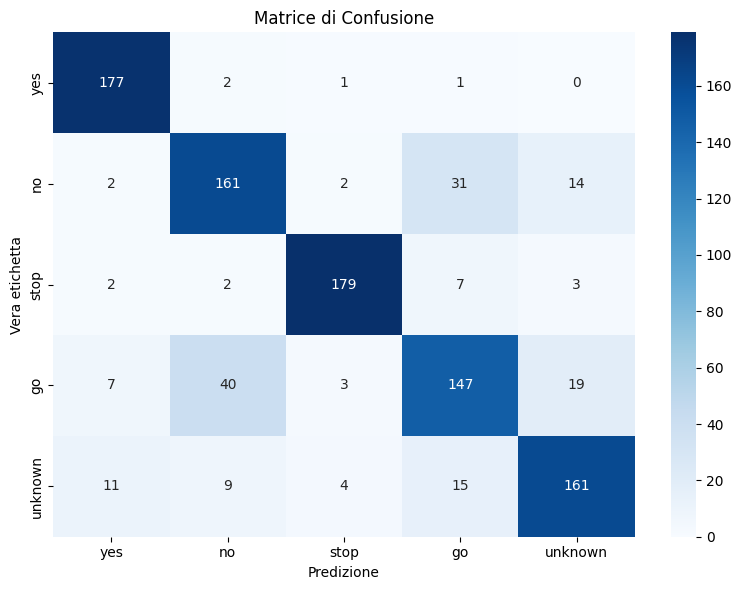


--- REPORT PER CLASSE ---
              precision    recall  f1-score   support

         yes       0.89      0.98      0.93       181
          no       0.75      0.77      0.76       210
        stop       0.95      0.93      0.94       193
          go       0.73      0.68      0.71       216
     unknown       0.82      0.81      0.81       200

    accuracy                           0.82      1000
   macro avg       0.83      0.83      0.83      1000
weighted avg       0.82      0.82      0.82      1000



In [14]:
# --- IMPORT NECESSARI (Li mettiamo qui per sicurezza!) ---
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# --- IL TUO CODICE ---
# Versione veloce — predice tutto il validation set in un colpo solo
y_true = np.concatenate([y for _, y in val_ds])
y_pred = np.argmax(model.predict(val_ds, verbose=1), axis=1)

# Matrice di confusione
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=commands, yticklabels=commands)
plt.title('Matrice di Confusione')
plt.ylabel('Vera etichetta')
plt.xlabel('Predizione')
plt.tight_layout()
plt.show()

print("\n--- REPORT PER CLASSE ---")
print(classification_report(y_true, y_pred,
                             labels=list(range(len(commands))),
                             target_names=commands))

Accuracy per classe

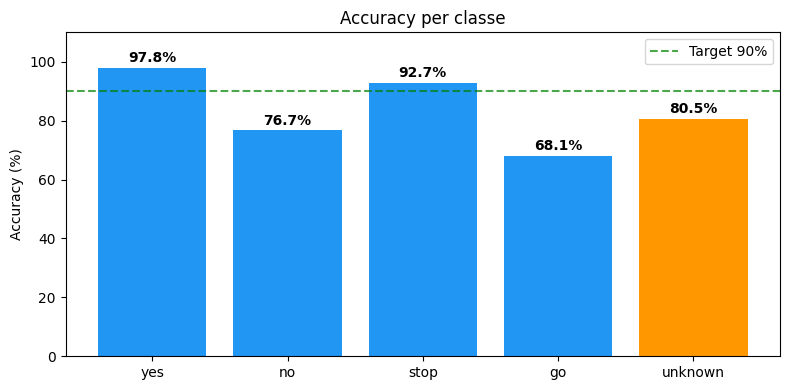

In [15]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8, 4))
bars = plt.bar(commands, per_class_acc * 100, color=['#2196F3']*4 + ['#FF9800'])
plt.axhline(y=90, color='green', linestyle='--', alpha=0.7, label='Target 90%')
plt.ylim(0, 110)
plt.ylabel('Accuracy (%)')
plt.title('Accuracy per classe')
plt.legend()

for bar, acc in zip(bars, per_class_acc):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'{acc*100:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

Grafici di training

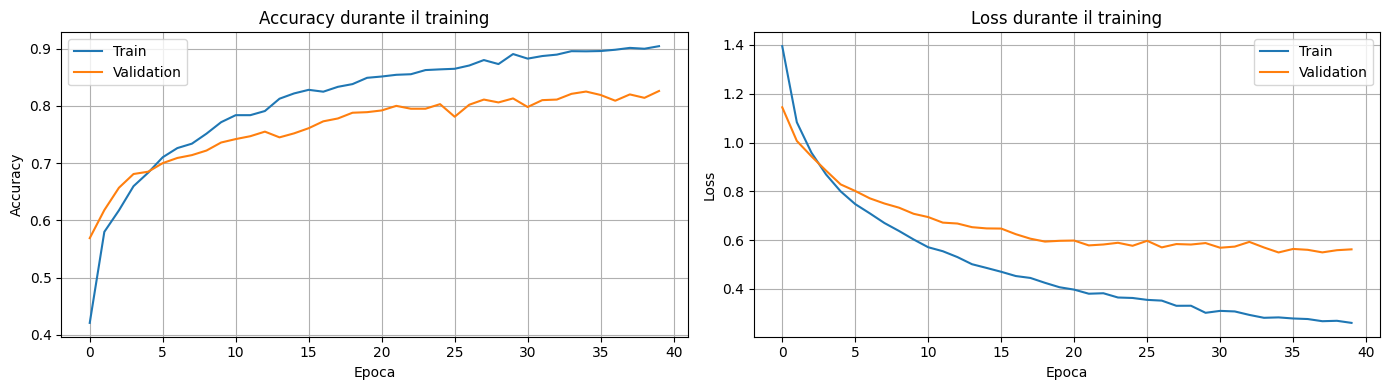

In [16]:
# CELLA — Grafici di training
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['accuracy'],     label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy durante il training')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['loss'],     label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss durante il training')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Esempi di spettrogrammi per classse

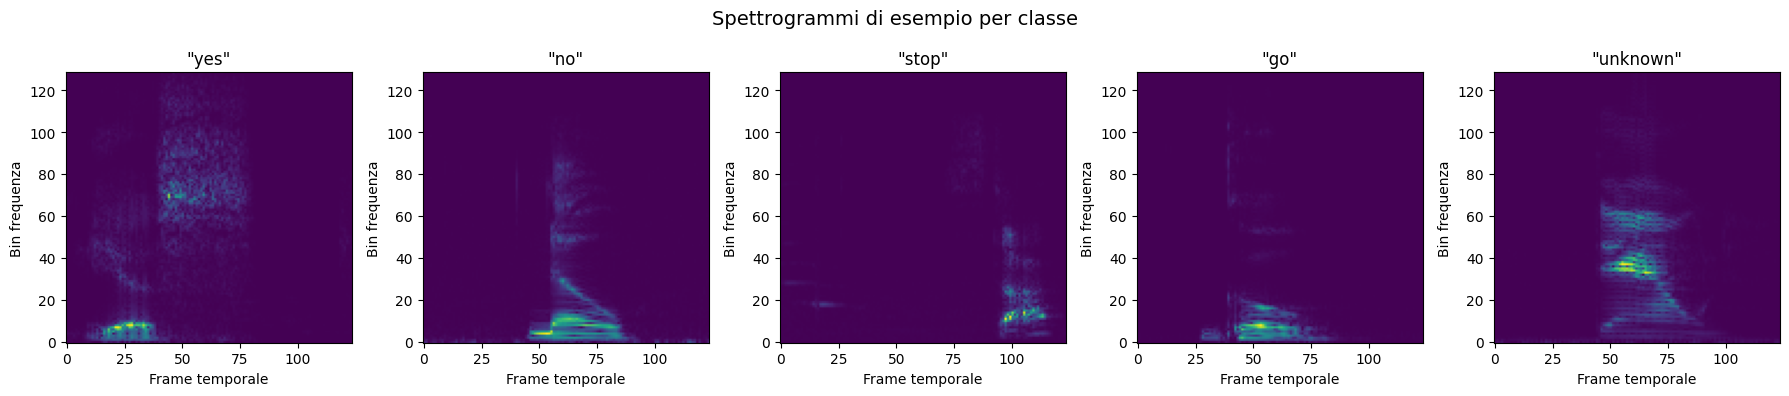

In [17]:
fig, axes = plt.subplots(1, len(commands), figsize=(18, 4))

for idx, cmd in enumerate(commands):
    # Trova il primo esempio di questa classe
    for spec, label in val_ds.unbatch():
        if label.numpy() == idx:
            axes[idx].imshow(
                spec.numpy().squeeze().T,
                origin='lower',
                aspect='auto',
                cmap='viridis'
            )
            axes[idx].set_title(f'"{cmd}"')
            axes[idx].set_xlabel('Frame temporale')
            axes[idx].set_ylabel('Bin frequenza')
            break

plt.suptitle('Spettrogrammi di esempio per classe', fontsize=14)
plt.tight_layout()
plt.show()

Estrazione array audio grezzo parole di prova

In [18]:
import numpy as np
import scipy.io.wavfile as wavfile

commands = ["yes", "no", "stop", "go", "unknown"]
found_classes = {0: False, 1: False, 2: False, 3: False, 4: False}

print("🔍 Estrazione audio GREZZO dai percorsi del Validation Set...")

# Scorriamo la lista esatta dei file di validazione
for file_path in val_files:
    # A seconda di come è salvato, estraiamo la stringa del percorso
    path_str = file_path.numpy().decode('utf-8') if hasattr(file_path, 'numpy') else str(file_path)

    # Determiniamo a quale classe appartiene guardando il nome della cartella
    if '/yes/' in path_str: label_idx = 0
    elif '/no/' in path_str: label_idx = 1
    elif '/stop/' in path_str: label_idx = 2
    elif '/go/' in path_str: label_idx = 3
    else: label_idx = 4 # unknown (es. left, right)

    # Se non abbiamo ancora salvato questa classe, la lavoriamo
    if not found_classes[label_idx]:
        # 1. Legge il .wav ORIGINALE senza fare l'STFT
        sample_rate, data = wavfile.read(path_str)
        if len(data.shape) > 1: data = data[:, 0]

        # 2. Porta a 16000 campioni esatti
        if len(data) > 16000: data = data[:16000]
        elif len(data) < 16000: data = np.pad(data, (0, 16000 - len(data)), 'constant')

        # 3. Formatta in C (sicuro senza troncamenti)
        audio_list = data.tolist()
        array_name = f"raw_audio_{commands[label_idx]}"

        c_code = f"const int16_t {array_name}[16000] = {{\n    "
        c_code += ", ".join(map(str, audio_list))
        c_code += "\n};\n"

        filename = f"{array_name}.txt"
        with open(filename, "w") as f:
            f.write(c_code)

        print(f"✅ Generato {filename} dal file: {path_str}")
        found_classes[label_idx] = True

    # Se le abbiamo trovate tutte e 5, fermiamo il ciclo
    if all(found_classes.values()):
        break

print("\n🎉 Finito! Questi sono i file del Validation Set veri e intatti.")

🔍 Estrazione audio GREZZO dai percorsi del Validation Set...
✅ Generato raw_audio_yes.txt dal file: data/mini_speech_commands_extracted/mini_speech_commands/yes/c22d3f18_nohash_1.wav
✅ Generato raw_audio_no.txt dal file: data/mini_speech_commands_extracted/mini_speech_commands/no/a60a09cf_nohash_1.wav
✅ Generato raw_audio_stop.txt dal file: data/mini_speech_commands_extracted/mini_speech_commands/stop/d0426d63_nohash_1.wav
✅ Generato raw_audio_go.txt dal file: data/mini_speech_commands_extracted/mini_speech_commands/go/a879a2c3_nohash_0.wav
✅ Generato raw_audio_unknown.txt dal file: data/mini_speech_commands_extracted/mini_speech_commands/down/3f170018_nohash_0.wav

🎉 Finito! Questi sono i file del Validation Set veri e intatti.


Test finale su tutti gli audio estratti per test

In [19]:
import numpy as np
import tensorflow as tf
import re
import os

# Dizionario COMPLETO con i 5 file .txt che hai generato
txt_files = {
    "yes": "raw_audio_yes.txt",
    "no": "raw_audio_no.txt",
    "stop": "raw_audio_stop.txt",
    "go": "raw_audio_go.txt",
    "unknown": "raw_audio_unknown.txt"
}

# Assicurati che l'ordine sia quello del tuo modello
commands = ["yes", "no", "stop", "go", "unknown"]

def load_audio_from_c_array(filepath):
    """Legge un file .txt formattato in C e restituisce un array Numpy di float32"""
    with open(filepath, 'r') as f:
        content = f.read()

    # Cerca tutto quello che c'è tra le parentesi graffe { ... }
    match = re.search(r'\{([^}]+)\}', content)
    if match:
        numbers_str = match.group(1)
        # Separa i numeri per virgola, rimuove gli spazi e li converte
        raw_audio = np.array([float(x.strip()) for x in numbers_str.split(',')], dtype=np.float32)
        return raw_audio
    else:
        raise ValueError(f"Impossibile leggere l'array dal file {filepath}")

print("🎙️ TEST TFLITE CON GLI ARRAY DELLA STM32 🎙️\n")

# Inizializza l'interprete una volta sola per velocizzare
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
input_index = interpreter.get_input_details()[0]['index']
output_index = interpreter.get_output_details()[0]['index']

for true_label, filename in txt_files.items():
    if not os.path.exists(filename):
        print(f"⚠️ File {filename} non trovato su Colab. Saltato.")
        continue

    # 1. Estrae i 16000 campioni dal file di testo e normalizza (/ 32768.0)
    raw_audio = load_audio_from_c_array(filename)
    waveform_test = tf.constant(raw_audio / 32768.0, dtype=tf.float32)

    # 2. Pre-processing (Spettrogramma)
    spec_test = get_spectrogram(waveform_test)
    input_tensor = spec_test[tf.newaxis, ...]

    # 3. Inferenza con TFLite
    interpreter.set_tensor(input_index, input_tensor)
    interpreter.invoke()
    predictions = interpreter.get_tensor(output_index)[0]

    # 4. Stampa i risultati con le barre grafiche
    print("=" * 50)
    print(f"📄 Lettura dal file: {filename}")
    print(f"🎯 Classe reale attesa: {true_label.upper()}")
    print("--- RISULTATI ---")

    for word, prob in zip(commands, predictions):
        # Disegna la barra ASCII per visualizzare la confidenza
        bars = '█' * int(prob * 40)
        print(f"{word:<7s}: {prob:.4f}  {bars}")

    best_idx = np.argmax(predictions)
    print(f"\n✅ Predizione finale: {commands[best_idx].upper()} ({predictions[best_idx]*100:.1f}%)")

print("=" * 50)

🎙️ TEST TFLITE CON GLI ARRAY DELLA STM32 🎙️

📄 Lettura dal file: raw_audio_yes.txt
🎯 Classe reale attesa: YES
--- RISULTATI ---
yes    : 1.0000  ████████████████████████████████████████
no     : 0.0000  
stop   : 0.0000  
go     : 0.0000  
unknown: 0.0000  

✅ Predizione finale: YES (100.0%)
📄 Lettura dal file: raw_audio_no.txt
🎯 Classe reale attesa: NO
--- RISULTATI ---
yes    : 0.0001  
no     : 0.7283  █████████████████████████████
stop   : 0.0044  
go     : 0.0747  ██
unknown: 0.1924  ███████

✅ Predizione finale: NO (72.8%)
📄 Lettura dal file: raw_audio_stop.txt
🎯 Classe reale attesa: STOP
--- RISULTATI ---
yes    : 0.0384  █
no     : 0.1550  ██████
stop   : 0.7817  ███████████████████████████████
go     : 0.0035  
unknown: 0.0214  

✅ Predizione finale: STOP (78.2%)
📄 Lettura dal file: raw_audio_go.txt
🎯 Classe reale attesa: GO
--- RISULTATI ---
yes    : 0.0001  
no     : 0.1693  ██████
stop   : 0.0226  
go     : 0.7789  ███████████████████████████████
unknown: 0.0291  █

✅ Predi

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
